<a href="https://colab.research.google.com/github/aqshal36/Machine-Learning/blob/main/Tugas3_MachineLearning_AqshalRamadhanu.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Customer Personality Analysis - Unsupervised Learning Tugas 3


import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns

# Step 1: Load dataset

In [3]:
df = pd.read_csv('cpa.csv', sep='\t')

print('Jumlah baris & kolom:', df.shape)
df.head()

Jumlah baris & kolom: (2240, 29)


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


#Step2: lakukan Eksplorasi awal

Info Stuktur & tipe data
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   object 
 3   Marital_Status       2240 non-null   object 
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   object 
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurch

,count,mean,std,min,25%,50%,75%,max
ID,2240.0,5592.16,3246.66,0.0,2828.25,5458.5,8427.75,11191.0
Year_Birth,2240.0,1968.81,11.98,1893.0,1959.00,1970.0,1977.00,1996.0
Income,2216.0,52247.25,25173.08,1730.0,35303.00,51381.5,68522.00,666666.0
Kidhome,2240.0,0.44,0.54,0.0,0.00,0.0,1.00,2.0
Teenhome,2240.0,0.51,0.54,0.0,0.00,0.0,1.00,2.0
Recency,2240.0,49.11,28.96,0.0,24.00,49.0,74.00,99.0
MntWines,2240.0,303.94,336.60,0.0,23.75,173.5,504.25,1493.0
MntFruits,2240.0,26.30,39.77,0.0,1.00,8.0,33.00,199.0
MntMeatProducts,2240.0,166.95,225.72,0.0,16.00,67.0,232.00,1725.0
MntFishProducts,2240.0,37.53,54.63,0.0,3.00,12.0,50.00,259.0



Distribusi fitur kategori
Education
Graduation    1127
PhD            486
Master         370
2n Cycle       203
Basic           54
Name: count, dtype: int64 

Marital_Status
Married     864
Together    580
Single      480
Divorced    232
Widow        77
Alone         3
Absurd        2
YOLO          2
Name: count, dtype: int64 



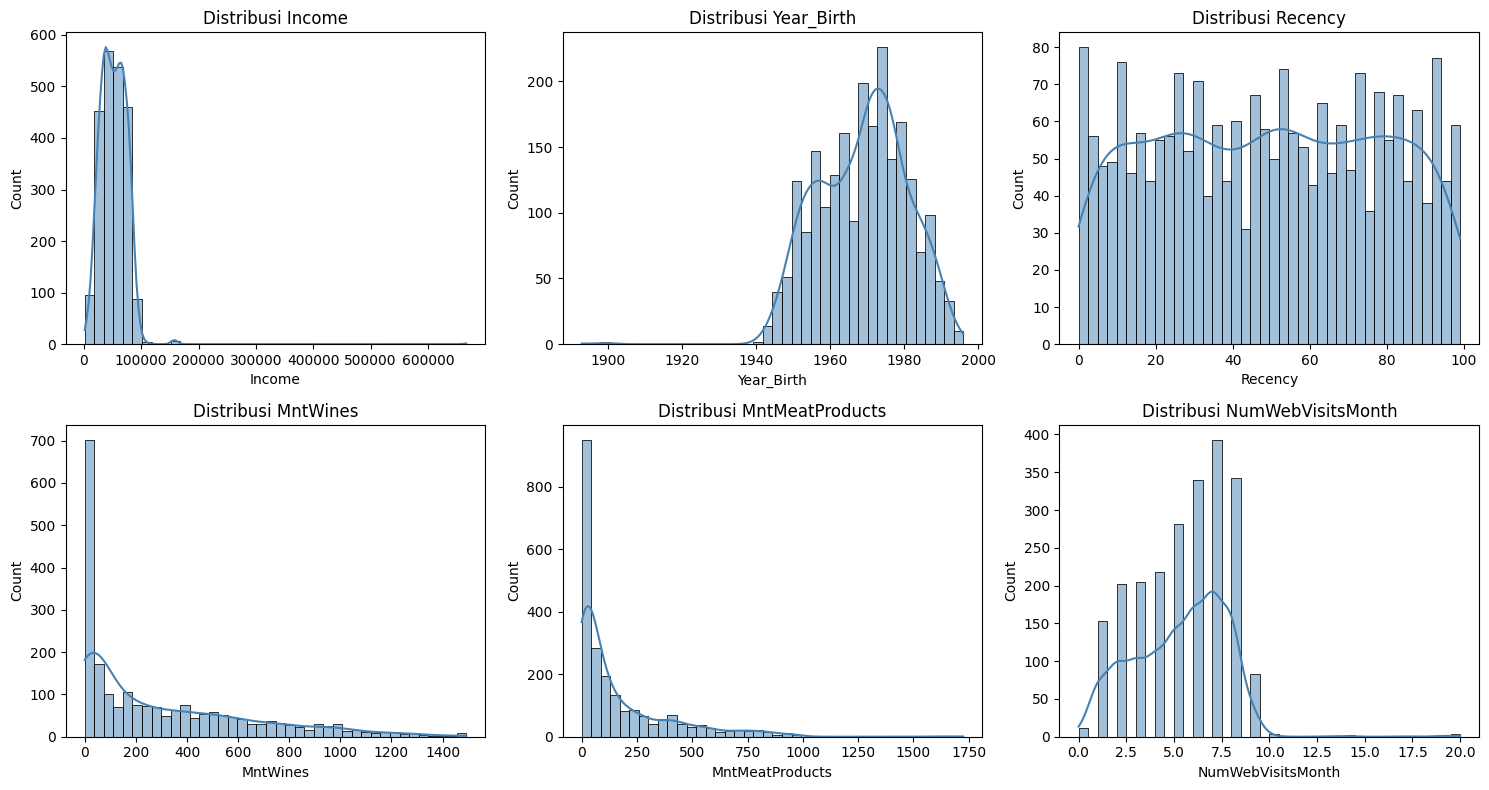

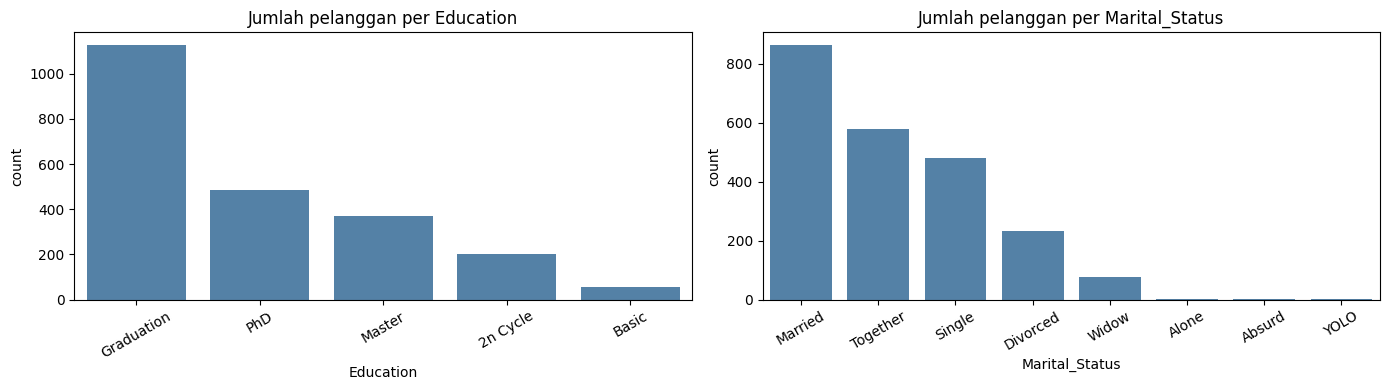

In [13]:
print('Info Stuktur & tipe data')
df.info()

mv = df.isnull().sum()
print('\n Kolom yang memiliki missing value')
print(pd.DataFrame({'Jumlah Missing Value': mv, 'persen (%)': (mv / len(df) * 100).round(2)})[mv > 0])
print('\nJumlahbaris duplikat:', df.duplicated().sum())

print('\nStatistik deskriptif (numerik)')
display(df.describe().T.round(2))

print('\nDistribusi fitur kategori')
for c in ['Education', 'Marital_Status']:
    print(df[c].value_counts(), '\n')

fitur_utama = ['Income', 'Year_Birth', 'Recency', 'MntWines', 'MntMeatProducts', 'NumWebVisitsMonth']
fig, axes = plt.subplots(2, 3, figsize=(15,8))
for ax, col in zip(axes.ravel(), fitur_utama):
    sns.histplot(df[col].dropna(), bins=40, kde=True, ax=ax, color='steelblue')
    ax.set_title(f'Distribusi {col}')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14,4))
for ax, col in zip(axes, ['Education', 'Marital_Status']):
    sns.countplot(data=df, x=col, order=df[col].value_counts().index, ax=ax, color='steelblue')
    ax.set_title(f'Jumlah pelanggan per {col}')
    ax.tick_params(axis='x', roration=30)
plt.tight_layout()
plt.show()



### Temuan eksplorasi data awal

- **Ukuran & tipe:** 2.240 pelanggan × 29 kolom (26 numerik, 3 teks: `Education`, `Marital_Status`, `Dt_Customer`).
- **Missing value:** hanya `Income` (24 baris ≈ 1,07%). Fitur kategori lengkap. Tidak ada baris duplikat.
- **Kolom tidak informatif:** `ID` hanya pengenal unik; `Z_CostContact` (=3) dan `Z_Revenue` (=11) konstan sehingga tidak membedakan pelanggan.
- **Outlier / data tidak wajar:** `Income` maksimum 666.666 padahal median ≈ 51.382 dan 75% data ≤ 68.522; `Year_Birth` minimum 1893 (umur > 120 tahun).
- **Distribusi:** `Income` dan semua fitur belanja (`MntWines`, `MntMeatProducts`, dll.) miring ke kanan, yaitu sebagian besar pelanggan berbelanja kecil dan sedikit pelanggan berbelanja sangat besar.
- **Kategori:** `Education` memiliki 5 level (terbanyak *Graduation*). `Marital_Status` memiliki 3 level yang tidak lazim dengan frekuensi sangat kecil: *Alone* (3), *Absurd* (2), *YOLO* (2).
- **Format tanggal:** `Dt_Customer` berupa teks `dd-mm-yyyy`, perlu diubah menjadi fitur numerik.

# Step 3: Identifikasi kolom numerik & kategori

In [14]:
data=df.copy()

data['Dt_Customer'] = pd.to_datetime(data['Dt_Customer'], format='%d-%m-%Y')
ref_date = data['Dt_Customer'].max()
data['Costumer_Tenure_Days'] = (ref_date - data['Dt_Customer']).dt.days

data['Age'] = ref_date.year - data['Year_Birth']

drop_cols = ['ID', 'Year_Birth', 'Dt_Customer', 'Z_CostContact', 'Z_Revenue']
data = data.drop(columns=drop_cols)

cat_cols = data.select_dtypes(exclude='number').columns.tolist()
num_cols = data.select_dtypes(include='number').columns.tolist()

print('Kolom kategori (%d):' % len(cat_cols), cat_cols)
print('Kolom numeri (%d):' % len(num_cols))
print(num_cols)

Kolom kategori (2): ['Education', 'Marital_Status']
Kolom numeri (24):
['Income', 'Kidhome', 'Teenhome', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2', 'Complain', 'Response', 'Costumer_Tenure_Days', 'Age']


# Step 4: Imputasi missing value

In [20]:
num_imputer = SimpleImputer(strategy='median')
cat_imputer = SimpleImputer(strategy='most_frequent')

print('Missing value SEBELUM imputasi:', int(data.isnull().sum().sum()))

data_num = pd.DataFrame(num_imputer.fit_transform(data[num_cols]), columns=num_cols, index=data.index)
data_cat = pd.DataFrame(cat_imputer.fit_transform(data[cat_cols]), columns=cat_cols, index=data.index)

print('Missing value SESUDAH imputasi:', int(data_num.isnull().sum().sum() + data_cat.isnull().sum().sum()))
print('Median Income yang dipakai untuk mengisi:', num_imputer.statistics_[num_cols.index('Income')])


Missing value SEBELUM imputasi: 24
Missing value SESUDAH imputasi: 0
Median Income yang dipakai untuk mengisi: 51381.5


In [21]:
for col in ['Income', 'Age']:
    batas = data_num[col].quantile(0.99)
    print(f'{col}: maks sebelum = {data_num[col].max():,.0f} -> batas persenrtil 99 = {batas:,.0f}')
    data_num[col] = data_num[col].clip(upper=batas)

Income: maks sebelum = 666,666 -> batas persenrtil 99 = 94,438
Age: maks sebelum = 121 -> batas persenrtil 99 = 69


**Strategi imputasi**

- **Numerik → median.** Hanya `Income` yang kosong (24 baris). Karena distribusinya sangat miring dan punya outlier, median lebih kokoh daripada rata-rata.
- **Kategori → modus (*most frequent*).** Saat ini tidak ada missing di `Education` maupun `Marital_Status`, tetapi imputer kategori tetap dipasang agar alur preprocessing lengkap dan aman jika ada data kosong.
- Imputasi di-*fit* pada seluruh data karena ini analisis *unsupervised* (tidak ada pemisahan train/test).
- Setelah imputasi, outlier ekstrem pada `Income` dan `Age` di-*winsorize* pada persentil 99, karena K-Means berbasis jarak sehingga satu nilai ekstrem dapat menggeser pusat klaster dan merusak hasil scaling.


# Step 5: Encoding fitur kategori

In [31]:
encoder = OneHotEncoder(min_frequency=10, handle_unknown='infrequent_if_exist', sparse_output=False)
encoded = encoder.fit_transform(data_cat)

data_encoded = pd.DataFrame(encoded, columns=encoder.get_feature_names_out(cat_cols), index=data.index)

print('Kategori yang digabug sebagai infrequent:')
for nama, kat in zip(cat_cols, encoder.infrequent_categories_):
    print(f' {nama}:', list(kat) if kat is not None else '-')
print('\nKolom hasil encoding:', data_encoded.shape[1])
data_encoded.head()

Kategori yang digabug sebagai infrequent:
 Education: -
 Marital_Status: ['Absurd', 'Alone', 'YOLO']

Kolom hasil encoding: 11


,Education_2n Cycle,Education_Basic,Education_Graduation,Education_Master,Education_PhD,Marital_Status_Divorced,Marital_Status_Married,Marital_Status_Single,Marital_Status_Together,Marital_Status_Widow,Marital_Status_infrequent_sklearn
0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
2,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0


#Gabungkan data numerik & hasil encoding

In [33]:
X = pd.concat([data_num, data_encoded], axis=1)

print('Ukuran data gabungan:', X.shape)
print('Masih ada missing value?', X.isnull().sum().any())
X.head()

Ukuran data gabungan: (2240, 35)
Masih ada missing value? False


,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,...,Education_Basic,Education_Graduation,Education_Master,Education_PhD,Marital_Status_Divorced,Marital_Status_Married,Marital_Status_Single,Marital_Status_Together,Marital_Status_Widow,Marital_Status_infrequent_sklearn
0,58138.0,0.0,0.0,58.0,635.0,88.0,546.0,172.0,88.0,88.0,...,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1,46344.0,1.0,1.0,38.0,11.0,1.0,6.0,2.0,1.0,6.0,...,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
2,71613.0,0.0,0.0,26.0,426.0,49.0,127.0,111.0,21.0,42.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,26646.0,1.0,0.0,26.0,11.0,4.0,20.0,10.0,3.0,5.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,58293.0,1.0,0.0,94.0,173.0,43.0,118.0,46.0,27.0,15.0,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0


# Step 6: Scaling data

In [38]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print('Rata- rata maks (abs):', np.abs(X_scaled.mean(axis=0)).max().round(6))
print('Std min / max    :', X_scaled.std(axis=0).min().round(3), '/', X_scaled.std(axis=0).max().round(3))
pd.DataFrame(X_scaled, columns=X.columns).head()


Rata- rata maks (abs): 0.0
Std min / max    : 1.0 / 1.0


,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,...,Education_Basic,Education_Graduation,Education_Master,Education_PhD,Marital_Status_Divorced,Marital_Status_Married,Marital_Status_Single,Marital_Status_Together,Marital_Status_Widow,Marital_Status_infrequent_sklearn
0,0.309355,-0.825218,-0.929894,0.307039,0.983781,1.551577,1.679702,2.462147,1.476500,0.843207,...,-0.157171,0.993769,-0.444816,-0.526385,-0.339909,-0.792406,1.914854,-0.591099,-0.188676,-0.055989
1,-0.261949,1.032559,0.906934,-0.383664,-0.870479,-0.636301,-0.713225,-0.650449,-0.631503,-0.729006,...,-0.157171,0.993769,-0.444816,-0.526385,-0.339909,-0.792406,1.914854,-0.591099,-0.188676,-0.055989
2,0.962086,-0.825218,-0.929894,-0.798086,0.362723,0.570804,-0.177032,1.345274,-0.146905,-0.038766,...,-0.157171,0.993769,-0.444816,-0.526385,-0.339909,-0.792406,-0.522233,1.691765,-0.188676,-0.055989
3,-1.216124,1.032559,-0.929894,-0.798086,-0.870479,-0.560857,-0.651187,-0.503974,-0.583043,-0.748179,...,-0.157171,0.993769,-0.444816,-0.526385,-0.339909,-0.792406,-0.522233,1.691765,-0.188676,-0.055989
4,0.316863,1.032559,-0.929894,1.550305,-0.389085,0.419916,-0.216914,0.155164,-0.001525,-0.556446,...,-0.157171,-1.006270,-0.444816,1.899751,-0.339909,1.261980,-0.522233,-0.591099,-0.188676,-0.055989



# Step 7: Tentukan jumlah cluster optimal (Elbow + Silhouette)

,k,inertia (WCSS),silhouette
0,2,66569.0,0.1759
1,3,62783.0,0.1064
2,4,60197.0,0.1093
3,5,57852.0,0.1233
4,6,56239.0,0.0796
5,7,54557.0,0.0975
6,8,53064.0,0.0777
7,9,51611.0,0.1063
8,10,49463.0,0.1086


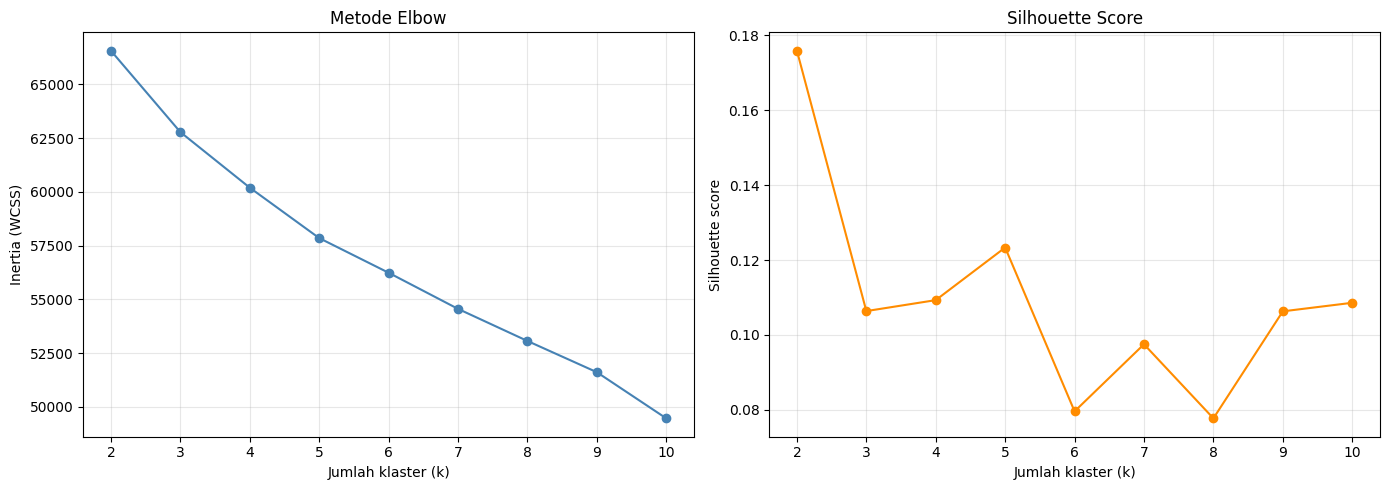

Silhouette tertinggi: k = 2 (skor 0.1759)


In [39]:
k_range = range(2, 11)
inertia, sil_scores = [], []

for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    lab = km.fit_predict(X_scaled)
    inertia.append(km.inertia_)
    sil_scores.append(silhouette_score(X_scaled, lab))

hasil_k = pd.DataFrame({'k': list(k_range), 'inertia (WCSS)': np.round(inertia, 0), 'silhouette': np.round(sil_scores, 4)})
display(hasil_k)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(list(k_range), inertia, marker='o', color='steelblue')
axes[0].set_title('Metode Elbow')
axes[0].set_xlabel('Jumlah klaster (k)')
axes[0].set_ylabel('Inertia (WCSS)')

axes[1].plot(list(k_range), sil_scores, marker='o', color='darkorange')
axes[1].set_title('Silhouette Score')
axes[1].set_xlabel('Jumlah klaster (k)')
axes[1].set_ylabel('Silhouette score')
for ax in axes:
    ax.set_xticks(list(k_range))
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

k_sil = list(k_range)[int(np.argmax(sil_scores))]
print(f'Silhouette tertinggi: k = {k_sil} (skor {max(sil_scores):.4f})')

In [43]:
from sklearn.metrics import adjusted_rand_score

lab5 = KMeans(n_clusters=5, n_init=10, random_state=42).fit_predict(X_scaled)
print('Komposissi Education per klaster pada k=5:')
display(pd.crosstab(pd.Series(lab5, name='Cluster'), data_cat['Education']))

lab4_ref = KMeans(n_clusters=4, n_init=10, random_state=42).fit_predict(X_scaled)
print('\nKestabilan k=4 terhadap seed berbeda (Adjusted Rand Index; 1 = identik):')
for seed in [0, 1, 7, 123]:
    lab4 = KMeans(n_clusters=4, n_init=10, random_state=seed).fit_predict(X_scaled)
    print(f'Seed {seed:>3}: ARI = {adjusted_rand_score(lab4_ref, lab4):.3f}')

Komposissi Education per klaster pada k=5:


Education,2n Cycle,Basic,Graduation,Master,PhD
Cluster,,,,,
0,113,0,503,161,186
1,32,0,268,127,177
2,12,0,88,28,42
3,0,54,0,0,0
4,46,0,268,54,81



Kestabilan k=4 terhadap seed berbeda (Adjusted Rand Index; 1 = identik):
Seed   0: ARI = 0.994
Seed   1: ARI = 0.976
Seed   7: ARI = 0.920
Seed 123: ARI = 0.996


### Pemilihan jumlah klaster

**Membaca grafik**

- **Elbow:** kurva inertia turun landai dan hampir linear, **tidak ada "siku" yang tajam**. Penurunan sedikit melambat di sekitar k = 3-5, tetapi tidak cukup tegas untuk menentukan k sendirian.
- **Silhouette:** tertinggi pada **k = 2 (0,176)**, kemudian k = 5 (0,123), k = 4 (0,109), dan k = 3 (0,106). Seluruh skor masih rendah (< 0,2), artinya pelanggan di dataset ini **tidak membentuk kelompok yang terpisah tegas**, melainkan lebih mirip spektrum (pendapatan dan belanja rendah → tinggi) yang dipotong menjadi beberapa segmen.

**Mengapa memilih k = 4 (bukan k = 2)?** Ini adalah keputusan kompromi, bukan k dengan silhouette tertinggi:

1. **k = 2 terlalu kasar.** Hasilnya hanya "belanja tinggi vs rendah" sehingga tidak cukup untuk menyusun strategi pemasaran yang berbeda.
2. **k = 5 tidak menambah segmen yang bermakna.** Klaster tambahannya hanya berisi 54 pelanggan dan identik dengan *seluruh* pelanggan berpendidikan `Basic`, jadi dipicu oleh satu kolom dummy hasil encoding, bukan oleh perilaku belanja (dibuktikan di sel di bawah).
3. **k = 4 memberi segmen yang jelas berbeda** dari sisi pendapatan, komposisi keluarga, pola belanja, dan respons kampanye. Segmen terkecil masih 7,6% dari pelanggan, dan hasilnya stabil terhadap inisialisasi acak yang berbeda.

# Step 8: Pilih k optimal dan klasterisasi

In [49]:
K_FINAL = 4

kmeans = KMeans(n_clusters=K_FINAL, n_init=10, random_state=42)
raw_labels = kmeans.fit_predict(X_scaled)

kolom_belanja = ['MntWines', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds']
total_belanja = X[kolom_belanja].sum(axis=1)
urutan = total_belanja.groupby(raw_labels).mean().sort_values().index
peta = {lama: baru for baru, lama in enumerate(urutan)}
labels = np.array([peta[l] for l in raw_labels])

print(f'Silhoutte score (k={K_FINAL}): {silhouette_score(X_scaled, labels):.4f}')
ukuran = pd.Series(labels).value_counts().sort_index()
print('\nJumlah pelanggan per klaster:')
print(pd.DataFrame({'Jumlah': ukuran, 'persen (%)': (ukuran / len(labels)* 100).round(1)}))


Silhoutte score (k=4): 0.1093

Jumlah pelanggan per klaster:
   Jumlah  persen (%)
0    1003        44.8
1     616        27.5
2     451        20.1
3     170         7.6


# Step 9: Visualisasi klaster dengan PCA 2D

Varians yang dijelaskan PC1 & PC2: [19.4  6.4] %
Total: 25.8 %


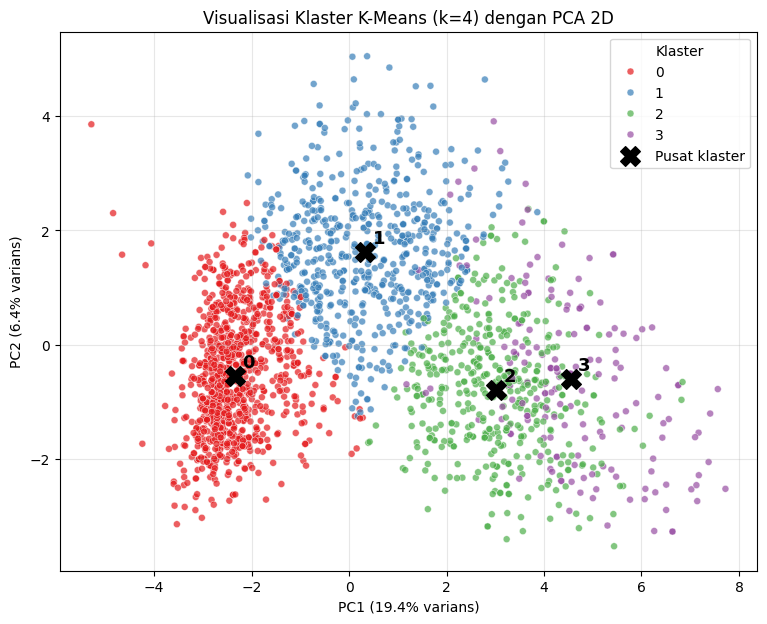

In [57]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

print('Varians yang dijelaskan PC1 & PC2:', (pca.explained_variance_ratio_ * 100).round(1), '%')
print('Total:', round(pca.explained_variance_ratio_.sum() * 100, 1), '%')

pca_df = pd.DataFrame({'PC1': X_pca[:, 0], 'PC2': X_pca[:, 1], 'Cluster': labels})

plt.figure(figsize=(9,7))
sns.scatterplot(data=pca_df, x='PC1', y='PC2', hue='Cluster', palette='Set1', s=25, alpha=0.7)

pusat = pca_df.groupby('Cluster')[['PC1', 'PC2']].mean()
plt.scatter(pusat['PC1'], pusat['PC2'], c='black', marker='X', s=200, label='Pusat klaster')
for c, row in pusat.iterrows():
      plt.text(row['PC1'] + 0.15, row['PC2'] + 0.15, str(c), fontsize=13, fontweight='bold')

plt.title(f'Visualisasi Klaster K-Means (k={K_FINAL}) dengan PCA 2D')
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0] * 100:.1f}% varians)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1] * 100:.1f}% varians)')
plt.legend(title='Klaster')
plt.grid(alpha=0.3)
plt.show()

- PC1 dan PC2 hanya menjelaskan **25,8%** varians total (19,4% + 6,4%), sehingga plot 2D hanya menangkap sebagian struktur data dan sebagian tumpang tindih antar klaster adalah akibat proyeksi.
- Klaster tersusun searah PC1 dari kiri ke kanan (0 → 1 → 2 → 3), searah dengan naiknya pendapatan dan total belanja. Klaster 0 paling terpisah dari yang lain.
- **Klaster 2 dan 3 saling tumpang tindih cukup banyak.** Keduanya sama-sama berpendapatan tinggi, dan pembedanya (respons terhadap kampanye) kurang tertangkap oleh dua komponen pertama.
- Pola ini konsisten dengan silhouette yang rendah: segmentasi ini sebaiknya dibaca sebagai **gradasi segmen**, bukan kelompok yang benar-benar terpisah.

# Step 10: Profiling cluster (rata-rata fitur per cluster)

In [64]:
profil = data_num.copy()
profil['Total_Spend'] = profil[kolom_belanja].sum(axis=1)
profil['Total_Purchases'] = profil[['NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases']].sum(axis=1)
profil['Total_CampaignAccepted'] = profil[['AcceptedCmp1', 'AcceptedCmp2', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5']].sum(axis=1)
profil['Cluster'] = labels

kolom_profil = ['Income', 'Age', 'Kidhome', 'Teenhome', 'Costumer_Tenure_Days', 'Recency',
                'Total_Spend', 'MntWines', 'MntMeatProducts', 'MntGoldProds',
                'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases',
                'NumWebVisitsMonth', 'Total_CampaignAccepted', 'Response']

ringkas = profil.groupby('Cluster')[kolom_profil].mean().round(2)
ringkas.insert(0, 'Jumlah', profil['Cluster'].value_counts().sort_index())
display(ringkas.T)

Cluster,0,1,2,3
Jumlah,1003.00,616.00,451.00,170.00
Income,34222.27,56965.92,72405.35,81488.30
Age,41.92,49.87,45.98,44.44
Kidhome,0.81,0.25,0.05,0.05
Teenhome,0.43,0.93,0.24,0.13
Costumer_Tenure_Days,322.68,400.57,357.28,355.84
Recency,49.44,48.14,49.46,49.72
Total_Spend,64.78,543.26,750.16,1095.06
MntWines,37.10,440.97,495.02,874.78
MntMeatProducts,22.57,124.32,432.35,469.18


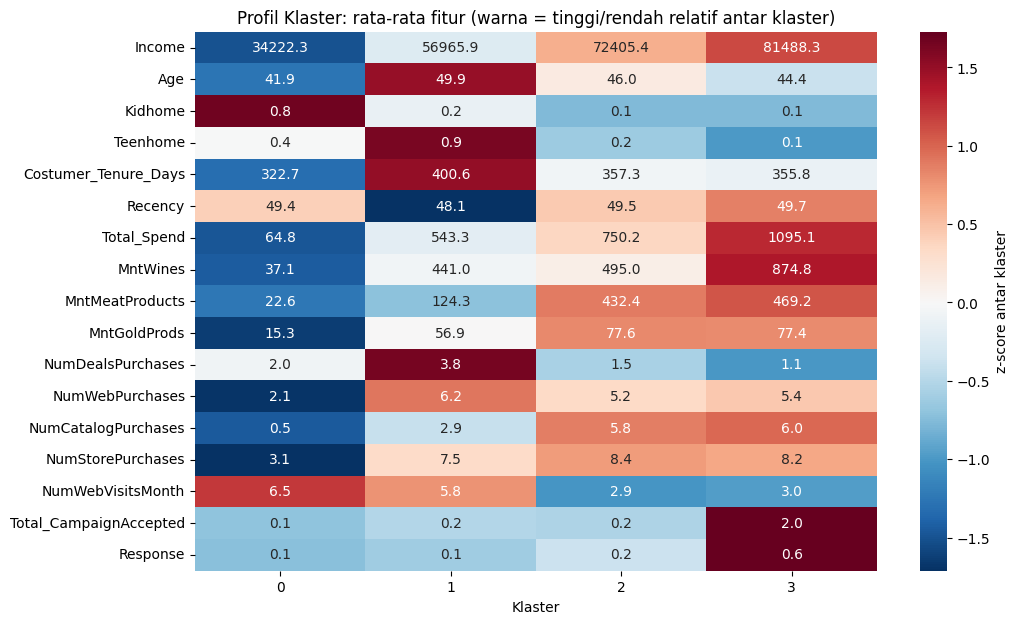

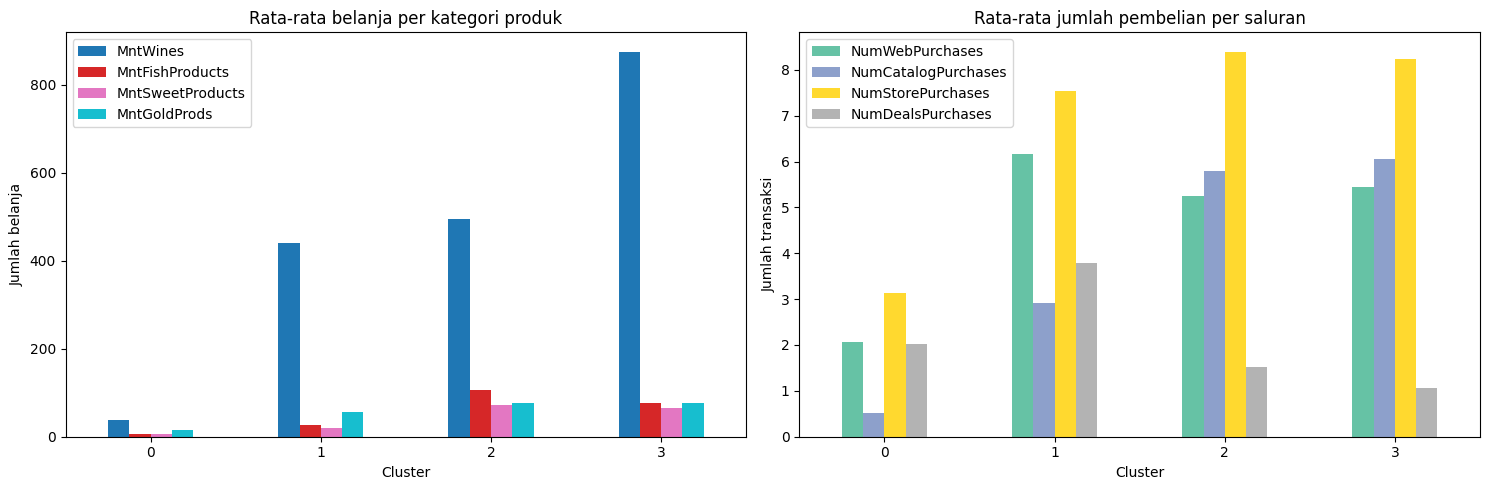


Education per klaster (%):


Education,2n Cycle,Basic,Graduation,Master,PhD
Cluster,,,,,
0,11.3,5.3,49.3,15.9,18.3
1,5.2,0.0,44.8,20.9,29.1
2,10.2,0.2,59.6,12.0,18.0
3,7.1,0.0,51.8,16.5,24.7



Marital_Status per klaster (%):


Marital_Status,Absurd,Alone,Divorced,Married,Single,Together,Widow,YOLO
Cluster,,,,,,,,
0,0.0,0.2,9.6,38.5,24.0,25.3,2.4,0.0
1,0.0,0.2,12.8,40.6,15.1,27.1,3.9,0.3
2,0.2,0.0,9.5,34.8,25.3,25.5,4.7,0.0
3,0.6,0.0,8.2,41.8,18.8,25.9,4.7,0.0


In [65]:
ringkas_z = (ringkas[kolom_profil] - ringkas[kolom_profil].mean()) / ringkas[kolom_profil].std(ddof=0)

plt.figure(figsize=(11, 7))
sns.heatmap(ringkas_z.T, annot=ringkas[kolom_profil].T, fmt='.1f', cmap='RdBu_r', center=0,
            cbar_kws={'label': 'z-score antar klaster'})
plt.title('Profil Klaster: rata-rata fitur (warna = tinggi/rendah relatif antar klaster)')
plt.xlabel('Klaster')
plt.show()

# Komposisi belanja per kategori produk & saluran pembelian
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
profil.groupby('Cluster')[kolom_belanja].mean().plot(kind='bar', ax=axes[0], colormap='tab10')
axes[0].set_title('Rata-rata belanja per kategori produk')
axes[0].set_ylabel('Jumlah belanja')
axes[0].tick_params(axis='x', rotation=0)

kolom_saluran = ['NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumDealsPurchases']
profil.groupby('Cluster')[kolom_saluran].mean().plot(kind='bar', ax=axes[1], colormap='Set2')
axes[1].set_title('Rata-rata jumlah pembelian per saluran')
axes[1].set_ylabel('Jumlah transaksi')
axes[1].tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

for c in ['Education', 'Marital_Status']:
    print(f'\n{c} per klaster (%):')
    display((pd.crosstab(pd.Series(labels, name='Cluster'), data_cat[c], normalize='index') * 100).round(1))

Nomor klaster diurutkan berdasarkan rata-rata total belanja (0 = terendah, 3 = tertinggi). Nilai `Income` memakai satuan mata uang di dataset.

| Klaster | Nama segmen | Jumlah | Ciri utama |
|---|---|---|---|
| **0** | **Hemat berkeluarga muda** | 1.003 (44,8%) | Pendapatan terendah (≈ 34 ribu), paling banyak anak kecil (0,81 per rumah tangga), belanja sangat rendah (≈ 92), paling sering membuka web (6,5 kunjungan/bulan) tetapi jarang membeli (web 2,1; katalog 0,5; toko 3,1). Pelanggan paling baru (± 323 hari). |
| **1** | **Keluarga remaja pemburu diskon** | 616 (27,5%) | Pendapatan menengah (≈ 57 ribu), paling banyak remaja di rumah (0,93), usia rata-rata tertinggi (≈ 50 tahun), pelanggan terlama (± 401 hari). Belanja menengah (≈ 687) dengan dominasi anggur. Paling sering membeli dengan diskon (3,8) dan paling banyak membeli lewat web (6,2). |
| **2** | **Mapan reguler** | 451 (20,1%) | Pendapatan tinggi (≈ 72 ribu), hampir tanpa anak kecil, belanja tinggi (≈ 1.254) pada anggur dan daging. Kuat di toko (8,4) dan katalog (5,8), jarang membuka web (2,9) dan jarang memakai diskon (1,5). Respons kampanye rendah (0,2 kampanye diterima). |
| **3** | **VIP responsif kampanye** | 170 (7,6%) | Pendapatan tertinggi (≈ 81 ribu), belanja tertinggi (≈ 1.620) dengan anggur sangat dominan (≈ 875). **Paling responsif terhadap pemasaran**: rata-rata menerima 2,0 kampanye dan 58% merespons penawaran terakhir (klaster lain 9-16%). Hampir tidak memakai diskon (1,1). |

**Catatan penting**

- Yang **membedakan** klaster adalah pendapatan, total dan komposisi belanja, komposisi keluarga (anak kecil vs remaja), saluran pembelian, dan respons kampanye.
- Yang **tidak membedakan** klaster: `Recency` (selisih antar klaster < 2 hari, warna pada heatmap hanya efek penskalaan z-score antar klaster) serta `Education` dan `Marital_Status` (distribusinya relatif mirip; perbedaan terbesar: klaster 1 punya porsi PhD tertinggi, 29,1%).
- Fitur turunan (`Total_Spend`, `Total_Purchases`, `Total_CampaignAccepted`) hanya dipakai untuk profiling, bukan untuk klastering, agar tidak terjadi penghitungan ganda.

# Simpulkan Analisa dari hasil


## Kesimpulan

**Proses.** Data 2.240 pelanggan dibersihkan (ID, `Z_*` konstan dibuang; `Year_Birth` dan `Dt_Customer` diubah menjadi `Age` dan `Customer_Tenure_Days`), missing `Income` diimputasi dengan median, outlier ekstrem `Income` dan `Age` di-*winsorize* pada persentil 99, fitur kategori di-*one-hot encode*, lalu semua fitur di-*standardize* sebelum K-Means.

**Pemilihan k.** Elbow tidak menunjukkan siku yang tegas dan silhouette tertinggi di k = 2 (0,176). Dipilih **k = 4** karena k = 2 terlalu kasar untuk keperluan pemasaran, sedangkan k = 5 hanya memisahkan 54 pelanggan berpendidikan *Basic* (artefak encoding). Silhouette k = 4 sebesar 0,109.

**Hasil segmentasi.**

1. **Hemat berkeluarga muda (44,8%)** — pendapatan rendah, anak kecil banyak, belanja minim, banyak berkunjung ke web tetapi jarang membeli.
2. **Keluarga remaja pemburu diskon (27,5%)** — pendapatan menengah, aktif membeli via web dan sangat sensitif terhadap diskon.
3. **Mapan reguler (20,1%)** — pendapatan tinggi, belanja besar di toko dan katalog (anggur + daging), jarang memakai diskon.
4. **VIP responsif kampanye (7,6%)** — pendapatan dan belanja tertinggi, paling responsif terhadap kampanye pemasaran.

**Implikasi bisnis (usulan)**

- **Klaster 0:** promosi paket hemat dan kebutuhan keluarga; pelajari penyebab tingginya kunjungan web tetapi rendahnya pembelian (harga, ongkos kirim, atau proses checkout).
- **Klaster 1:** program diskon, bundling, dan promo khusus web; segmen ini paling responsif terhadap harga.
- **Klaster 2:** katalog dan program loyalitas di toko, tawarkan produk premium (anggur, daging); tidak perlu diskon besar.
- **Klaster 3:** penawaran eksklusif, *early access*, dan layanan personal; segmen kecil tetapi bernilai tinggi dan paling mungkin menanggapi kampanye.

**Keterbatasan**

- Silhouette seluruh k rendah (< 0,2) dan PCA 2D hanya menjelaskan 25,8% varians, sehingga segmen bersifat **gradasi** dan klaster 2 dan 3 saling tumpang tindih.
- K-Means mengasumsikan klaster berbentuk bulat dengan ukuran serupa dan sensitif terhadap skala dan outlier. Winsorizing dan pemilihan fitur memengaruhi hasil.
- Data berupa potret periode 2012-2014 dan tidak ada label kebenaran untuk memvalidasi segmen.
- Langkah lanjutan yang dapat dicoba: seleksi fitur (mis. membuang dummy `Education`), algoritma lain (Hierarchical, Gaussian Mixture), atau validasi segmen dengan data pembelian periode berikutnya.